In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
train = pd.read_csv("../data/train.csv")
later = pd.read_csv("../data/later.csv")
holdout = pd.read_csv("../data/holdout_features.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("=" * 50)
print("DATASET DIMENSIONS")
print("=" * 50)

print(f"Training Dataset  : {train.shape}")
print(f"Later Dataset     : {later.shape}")
print(f"Holdout Dataset   : {holdout.shape}")

print("\nNumber of records:")
print(f"Train   : {len(train)}")
print(f"Later   : {len(later)}")
print(f"Holdout : {len(holdout)}")

DATASET DIMENSIONS
Training Dataset  : (1000, 12)
Later Dataset     : (300, 12)
Holdout Dataset   : (250, 10)

Number of records:
Train   : 1000
Later   : 300
Holdout : 250


In [4]:
print("TRAIN DATA")
display(train.head())

print("LATER DATA")
display(later.head())

print("HOLDOUT DATA")
display(holdout.head())

TRAIN DATA


,record_id,date,loom_age_yr,thread_count,power_cuts_min,weaver_exp_yr,humidity_pct,shift_hours,fabric,shed,metres_checked_at_folding,metres_per_shift
0,R00001,2026-01-01,0.0,185,11,25,65,8.9,polyester,Shed 1,60.3,60.5
1,R00002,2026-01-01,13.0,182,82,6,88,6.2,silk,Shed 1,43.1,42.7
2,R00003,2026-01-01,5.0,199,40,27,38,9.7,cotton,Shed 1,52.9,52.5
3,R00004,2026-01-01,5.0,196,57,8,45,11.7,cotton,Shed 1,51.7,51.6
4,R00005,2026-01-01,12.0,199,99,-1,83,7.2,cotton,Shed 2,38.2,37.1


LATER DATA


,record_id,date,loom_age_yr,thread_count,power_cuts_min,weaver_exp_yr,humidity_pct,shift_hours,fabric,shed,metres_checked_at_folding,metres_per_shift
0,R20001,2026-07-01,24,66,143,20,57,10.4,cotton,Shed 2,24.0,23.5
1,R20002,2026-07-01,3,155,154,11,30,6.4,polyester,Shed 1,7.1,8.3
2,R20003,2026-07-01,26,120,83,26,75,6.5,polyester,Shed 3,46.9,46.4
3,R20004,2026-07-01,21,69,79,17,61,8.9,polyester,Shed 2,38.7,37.9
4,R20005,2026-07-01,1,96,105,9,51,9.8,cotton,Shed 1,41.6,39.8


HOLDOUT DATA


,record_id,date,loom_age_yr,thread_count,power_cuts_min,weaver_exp_yr,humidity_pct,shift_hours,fabric,shed
0,R50001,2026-09-01,20,127,107,34,87,9.8,cotton,Shed 3
1,R50002,2026-09-01,1,154,97,25,82,9.4,silk,Shed 2
2,R50003,2026-09-01,11,51,163,34,36,10.2,silk,Shed 3
3,R50004,2026-09-01,29,143,134,6,56,9.0,silk,Shed 1
4,R50005,2026-09-01,16,112,153,32,81,9.5,cotton,Shed 3


In [5]:
print("TRAIN DATA - LAST 5 RECORDS")
display(train.tail())

print("LATER DATA - LAST 5 RECORDS")
display(later.tail())

print("HOLDOUT DATA - LAST 5 RECORDS")
display(holdout.tail())

TRAIN DATA - LAST 5 RECORDS


,record_id,date,loom_age_yr,thread_count,power_cuts_min,weaver_exp_yr,humidity_pct,shift_hours,fabric,shed,metres_checked_at_folding,metres_per_shift
995,R00996,2026-06-30,23.0,132,118,10,63,9.9,silk,Shed 3,22.9,22.7
996,R00997,2026-06-30,312.0,162,84,32,87,6.4,polyester,Shed 2,37.5,36.8
997,R00998,2026-06-30,336.0,139,0,26,38,8.2,cotton,Shed 2,48.5,48.5
998,R00999,2026-06-30,1.0,177,82,5,35,7.1,polyester,Shed 1,30.1,30.7
999,R01000,2026-06-30,3.0,158,20,28,72,9.3,silk,Shed 1,63.0,64.6


LATER DATA - LAST 5 RECORDS


,record_id,date,loom_age_yr,thread_count,power_cuts_min,weaver_exp_yr,humidity_pct,shift_hours,fabric,shed,metres_checked_at_folding,metres_per_shift
295,R20296,2026-08-31,9,128,135,14,51,11.3,silk,Shed 2,22.2,22.4
296,R20297,2026-08-31,10,73,99,26,76,11.7,polyester,Shed 2,40.2,40.4
297,R20298,2026-08-31,19,177,79,15,30,8.9,polyester,Shed 1,23.8,24.5
298,R20299,2026-08-31,24,172,149,34,38,9.7,cotton,Shed 2,18.5,17.5
299,R20300,2026-08-31,11,138,148,23,88,8.9,polyester,Shed 2,32.0,32.1


HOLDOUT DATA - LAST 5 RECORDS


,record_id,date,loom_age_yr,thread_count,power_cuts_min,weaver_exp_yr,humidity_pct,shift_hours,fabric,shed
245,R50246,2026-09-30,2,103,58,19,51,7.7,cotton,Shed 1
246,R50247,2026-09-30,28,168,169,20,50,10.7,cotton,Shed 1
247,R50248,2026-09-30,4,128,141,27,41,7.6,cotton,Shed 3
248,R50249,2026-09-30,6,176,93,14,51,10.7,cotton,Shed 2
249,R50250,2026-09-30,17,185,75,2,38,9.0,cotton,Shed 2


In [6]:
print("TRAIN DATA INFORMATION")
train.info()

print("\nLATER DATA INFORMATION")
later.info()

print("\nHOLDOUT DATA INFORMATION")
holdout.info()

TRAIN DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   record_id                  1000 non-null   object 
 1   date                       1000 non-null   object 
 2   loom_age_yr                1000 non-null   float64
 3   thread_count               1000 non-null   int64  
 4   power_cuts_min             1000 non-null   int64  
 5   weaver_exp_yr              1000 non-null   int64  
 6   humidity_pct               1000 non-null   int64  
 7   shift_hours                1000 non-null   float64
 8   fabric                     1000 non-null   object 
 9   shed                       1000 non-null   object 
 10  metres_checked_at_folding  1000 non-null   float64
 11  metres_per_shift           1000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 93.9+ KB

LATER DATA INFORMATION


In [7]:
print("TRAIN COLUMNS:")
print(train.columns.tolist())

print("\nLATER COLUMNS:")
print(later.columns.tolist())

print("\nHOLDOUT COLUMNS:")
print(holdout.columns.tolist())

TRAIN COLUMNS:
['record_id', 'date', 'loom_age_yr', 'thread_count', 'power_cuts_min', 'weaver_exp_yr', 'humidity_pct', 'shift_hours', 'fabric', 'shed', 'metres_checked_at_folding', 'metres_per_shift']

LATER COLUMNS:
['record_id', 'date', 'loom_age_yr', 'thread_count', 'power_cuts_min', 'weaver_exp_yr', 'humidity_pct', 'shift_hours', 'fabric', 'shed', 'metres_checked_at_folding', 'metres_per_shift']

HOLDOUT COLUMNS:
['record_id', 'date', 'loom_age_yr', 'thread_count', 'power_cuts_min', 'weaver_exp_yr', 'humidity_pct', 'shift_hours', 'fabric', 'shed']


In [8]:
print("TRAIN DATA STATISTICS")
display(train.describe(include="all").T)

print("LATER DATA STATISTICS")
display(later.describe(include="all").T)

print("HOLDOUT DATA STATISTICS")
display(holdout.describe(include="all").T)

TRAIN DATA STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,1000,1000,R00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,1000,181,2026-01-24,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loom_age_yr,1000.0,NaN,NaN,NaN,71.696,97.245423,0.0,12.0,22.0,108.0,360.0
thread_count,1000.0,NaN,NaN,NaN,118.811,46.064012,40.0,80.0,117.0,159.0,199.0
power_cuts_min,1000.0,NaN,NaN,NaN,59.149,34.267785,0.0,30.0,58.0,87.25,120.0
weaver_exp_yr,1000.0,NaN,NaN,NaN,16.65,10.536058,-1.0,8.0,16.0,26.0,35.0
humidity_pct,1000.0,NaN,NaN,NaN,60.15,17.469593,30.0,45.0,61.0,76.0,90.0
shift_hours,1000.0,NaN,NaN,NaN,8.923,1.740253,6.0,7.4,8.9,10.4,12.0
fabric,1000,18,cotton,446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shed,1000,3,Shed 3,385,NaN,NaN,NaN,NaN,NaN,NaN,NaN


LATER DATA STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,300,300,R20001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,300,62,2026-08-09,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loom_age_yr,300.0,NaN,NaN,NaN,14.653333,8.625223,0.0,7.0,14.0,22.0,30.0
thread_count,300.0,NaN,NaN,NaN,116.88,43.541226,41.0,78.0,115.0,155.0,200.0
power_cuts_min,300.0,NaN,NaN,NaN,116.94,34.051059,56.0,87.0,119.5,145.0,175.0
weaver_exp_yr,300.0,NaN,NaN,NaN,17.26,10.054986,0.0,9.0,18.0,26.0,35.0
humidity_pct,300.0,NaN,NaN,NaN,59.51,16.349953,30.0,46.0,59.0,73.0,89.0
shift_hours,300.0,NaN,NaN,NaN,9.015667,1.716413,6.0,7.5,8.95,10.425,12.0
fabric,300,3,cotton,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shed,300,3,Shed 3,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN


HOLDOUT DATA STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,250,250,R50001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,250,30,2026-09-21,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loom_age_yr,250.0,NaN,NaN,NaN,14.036,8.590804,0.0,7.0,13.0,21.0,30.0
thread_count,250.0,NaN,NaN,NaN,119.756,46.233306,42.0,78.5,120.5,161.0,199.0
power_cuts_min,250.0,NaN,NaN,NaN,114.556,34.649694,55.0,85.25,109.0,147.0,173.0
weaver_exp_yr,250.0,NaN,NaN,NaN,16.92,10.401653,0.0,7.0,17.0,26.0,35.0
humidity_pct,250.0,NaN,NaN,NaN,61.056,17.276771,31.0,46.25,60.5,77.0,90.0
shift_hours,250.0,NaN,NaN,NaN,9.1172,1.725402,6.0,7.6,9.2,10.675,12.0
fabric,250,3,cotton,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shed,250,3,Shed 2,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## missing values

In [9]:
print("MISSING VALUES IN TRAIN")
display(train.isnull().sum())

print("MISSING VALUES IN LATER")
display(later.isnull().sum())

print("MISSING VALUES IN HOLDOUT")
display(holdout.isnull().sum())

MISSING VALUES IN TRAIN


record_id                    0
date                         0
loom_age_yr                  0
thread_count                 0
power_cuts_min               0
weaver_exp_yr                0
humidity_pct                 0
shift_hours                  0
fabric                       0
shed                         0
metres_checked_at_folding    0
metres_per_shift             0
dtype: int64

MISSING VALUES IN LATER


record_id                    0
date                         0
loom_age_yr                  0
thread_count                 0
power_cuts_min               0
weaver_exp_yr                0
humidity_pct                 0
shift_hours                  0
fabric                       0
shed                         0
metres_checked_at_folding    0
metres_per_shift             0
dtype: int64

MISSING VALUES IN HOLDOUT


record_id         0
date              0
loom_age_yr       0
thread_count      0
power_cuts_min    0
weaver_exp_yr     0
humidity_pct      0
shift_hours       0
fabric            0
shed              0
dtype: int64

## duplicate records

In [11]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in later:", later.duplicated().sum())
print("Duplicate rows in holdout:", holdout.duplicated().sum())

Duplicate rows in train: 0
Duplicate rows in later: 0
Duplicate rows in holdout: 0


In [12]:
print("Duplicate Train IDs:", train["record_id"].duplicated().sum())
print("Duplicate Later IDs:", later["record_id"].duplicated().sum())
print("Duplicate Holdout IDs:", holdout["record_id"].duplicated().sum())

Duplicate Train IDs: 0
Duplicate Later IDs: 0
Duplicate Holdout IDs: 0


In [13]:
categorical_columns = ["fabric", "shed"]

for col in categorical_columns:

    print(f"\n{'=' * 40}")
    print(f"Column: {col}")
    print("=" * 40)

    print(train[col].value_counts(dropna=False))


Column: fabric
fabric
cotton        446
polyester     250
silk          154
cotton         21
COTTON         19
 cotton        19
cot.           16
Cotton         13
silk           12
 silk           9
polyester       7
Polyester       7
pol.            6
POLYESTER       6
SILK            5
 polyester      4
Silk            4
sil.            2
Name: count, dtype: int64

Column: shed
shed
Shed 3    385
Shed 2    370
Shed 1    245
Name: count, dtype: int64


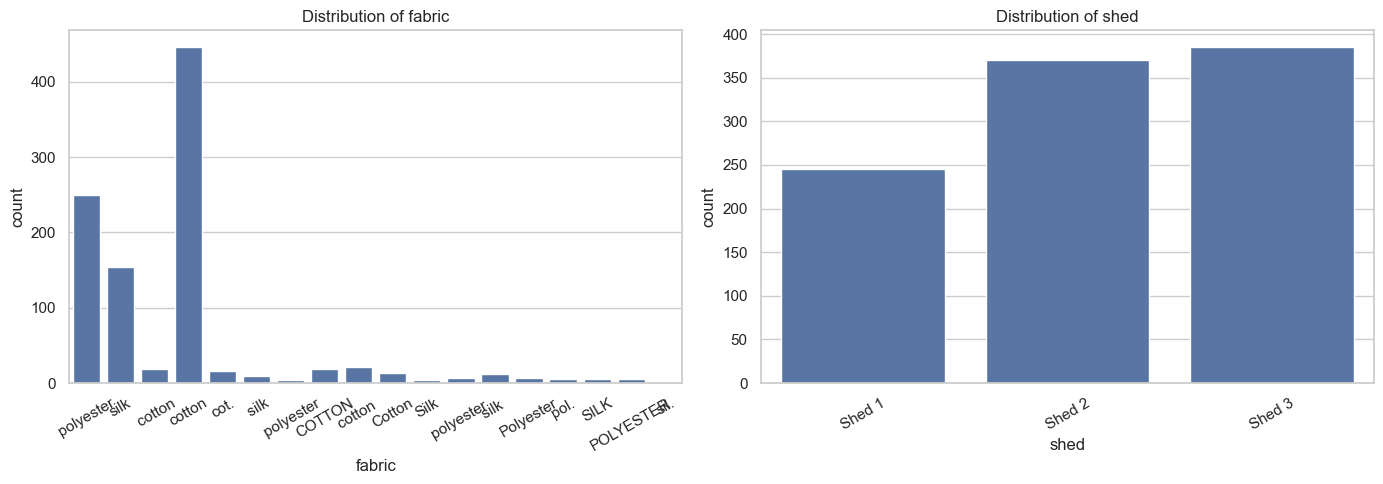

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, categorical_columns):

    sns.countplot(
        data=train,
        x=col,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Analyze numerical features

In [15]:
numeric_columns = train.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical Columns:")
print(numeric_columns)

print("\nNumerical Summary:")
display(train[numeric_columns].describe().T)

Numerical Columns:
['loom_age_yr', 'thread_count', 'power_cuts_min', 'weaver_exp_yr', 'humidity_pct', 'shift_hours', 'metres_checked_at_folding', 'metres_per_shift']

Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
loom_age_yr,1000.0,71.6960,97.245423,0.0,12.0,22.00,108.00,360.0
thread_count,1000.0,118.8110,46.064012,40.0,80.0,117.00,159.00,199.0
power_cuts_min,1000.0,59.1490,34.267785,0.0,30.0,58.00,87.25,120.0
weaver_exp_yr,1000.0,16.6500,10.536058,-1.0,8.0,16.00,26.00,35.0
humidity_pct,1000.0,60.1500,17.469593,30.0,45.0,61.00,76.00,90.0
shift_hours,1000.0,8.9230,1.740253,6.0,7.4,8.90,10.40,12.0
metres_checked_at_folding,1000.0,45.4871,11.250702,10.1,37.6,45.95,53.70,74.6
metres_per_shift,1000.0,45.4635,11.249733,9.6,37.5,45.90,53.60,73.6


## Distribution of numerical features

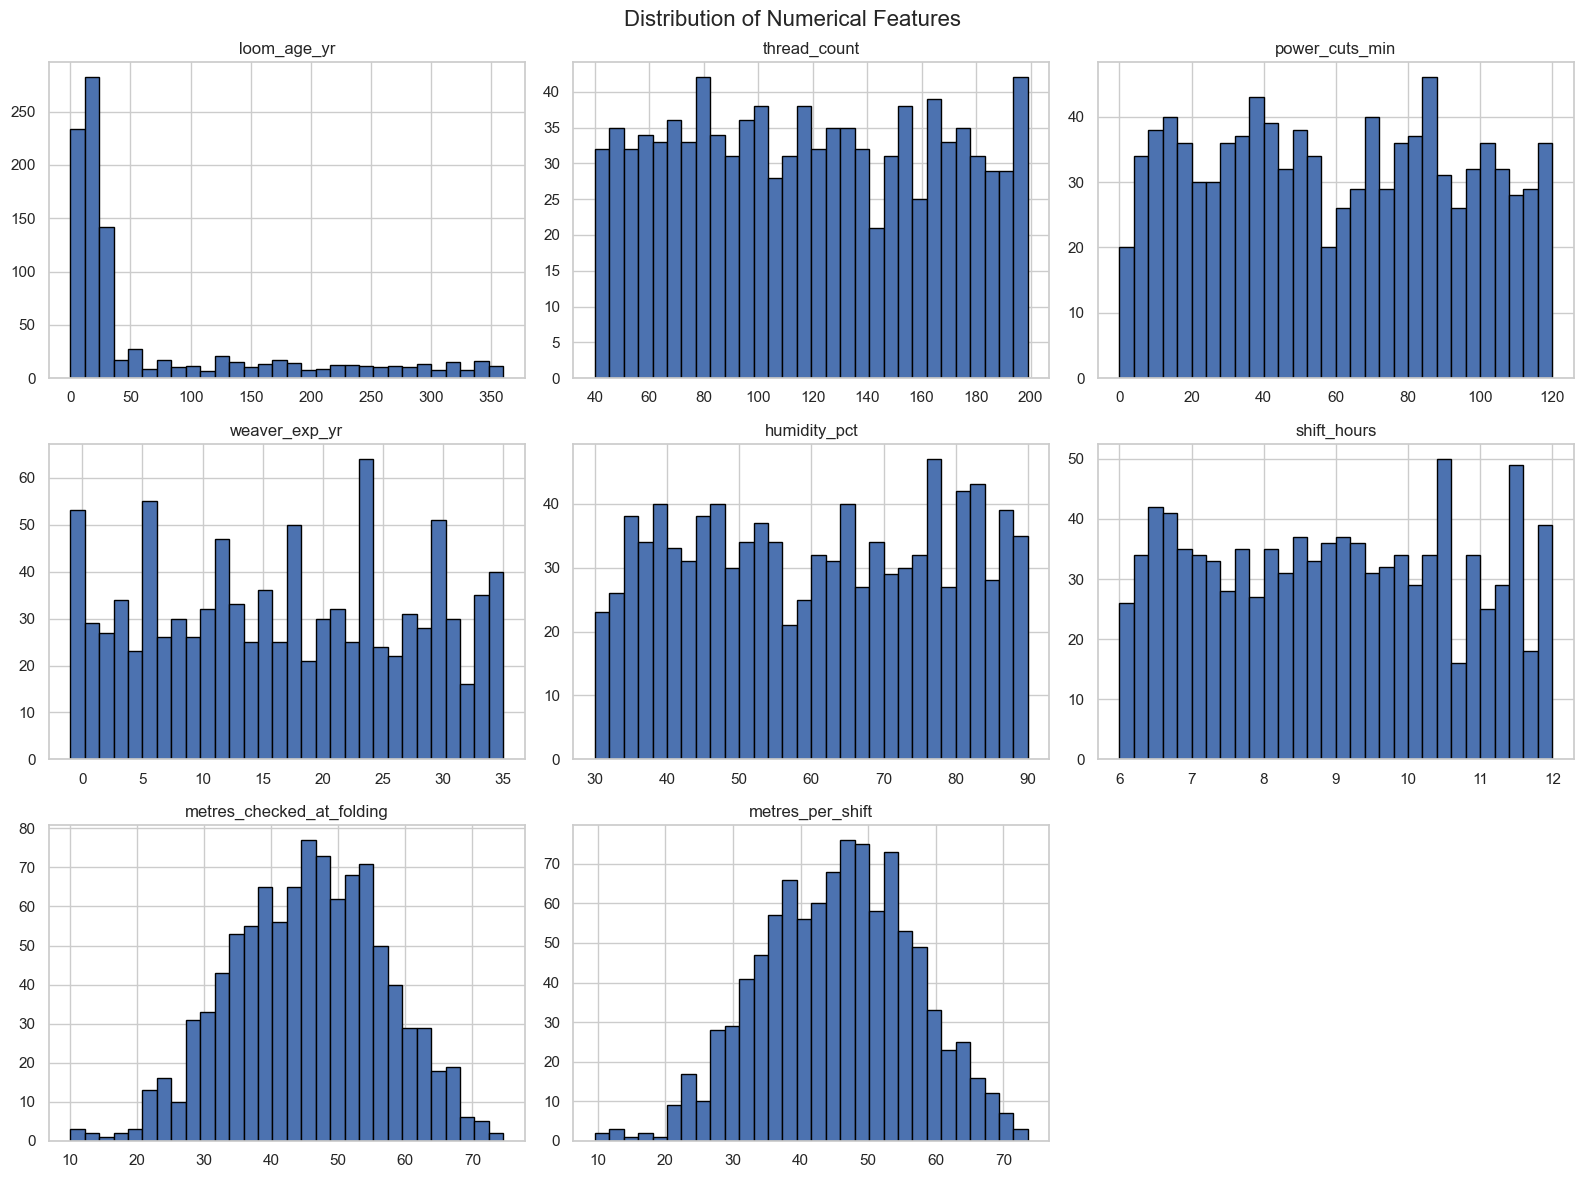

In [16]:
train[numeric_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Boxplots to identify potential outliers

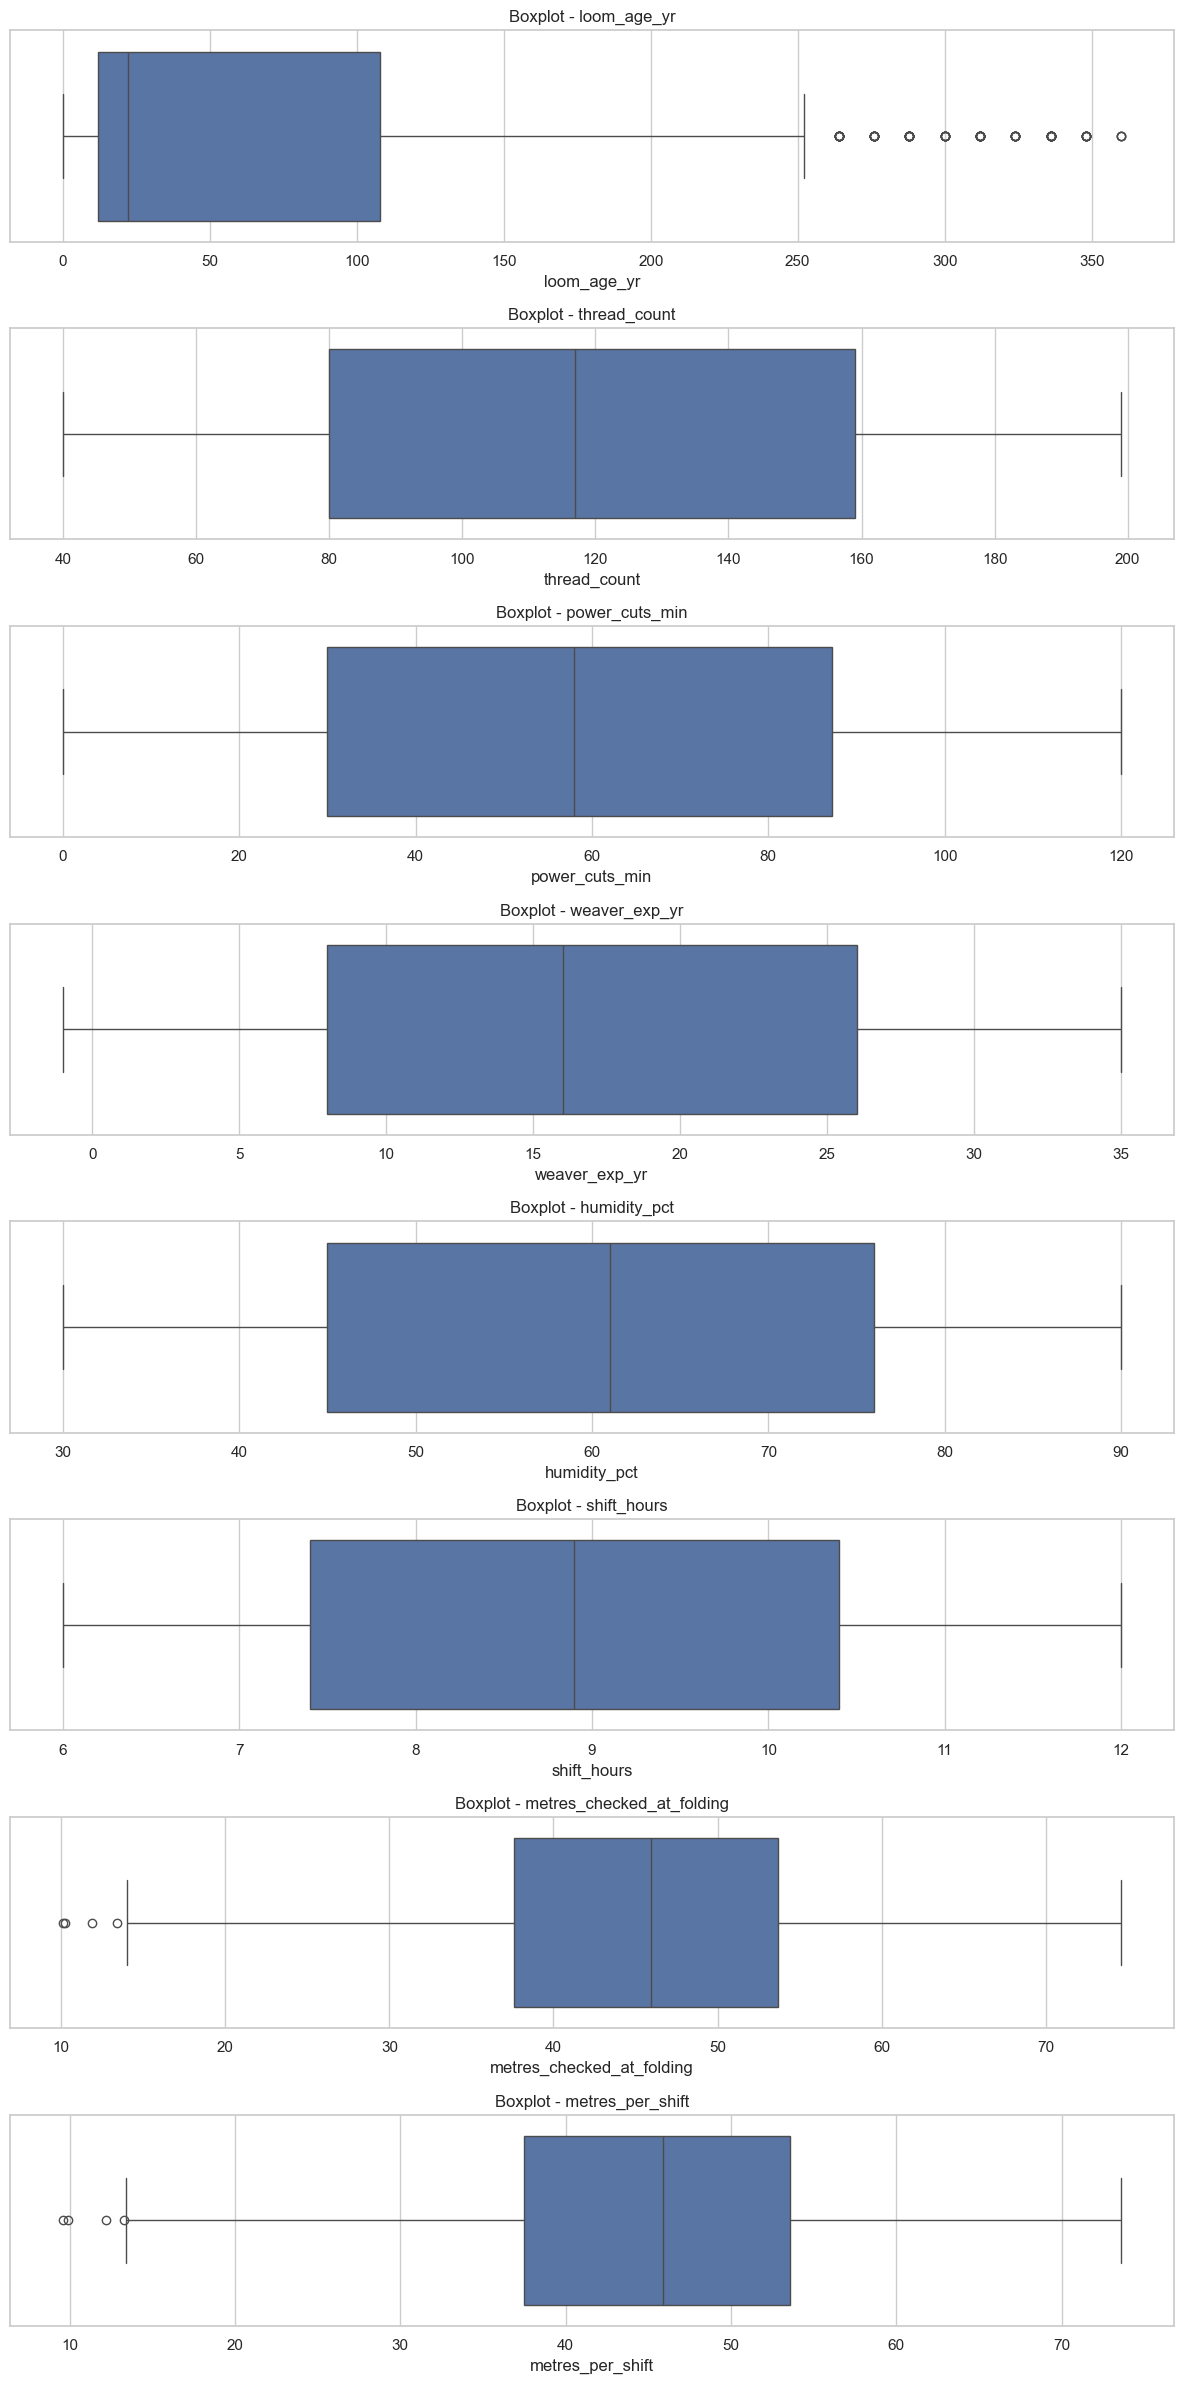

In [17]:
fig, axes = plt.subplots(
    len(numeric_columns),
    1,
    figsize=(12, 3 * len(numeric_columns))
)

for ax, col in zip(axes, numeric_columns):

    sns.boxplot(
        x=train[col],
        ax=ax
    )

    ax.set_title(f"Boxplot - {col}")

plt.tight_layout()
plt.show()

## Target variable analysis

In [18]:
print("TARGET VARIABLE SUMMARY")

display(train["metres_per_shift"].describe())

print("\nTarget minimum:", train["metres_per_shift"].min())
print("Target maximum:", train["metres_per_shift"].max())
print("Target mean:", train["metres_per_shift"].mean())
print("Target median:", train["metres_per_shift"].median())

TARGET VARIABLE SUMMARY


count    1000.000000
mean       45.463500
std        11.249733
min         9.600000
25%        37.500000
50%        45.900000
75%        53.600000
max        73.600000
Name: metres_per_shift, dtype: float64


Target minimum: 9.6
Target maximum: 73.6
Target mean: 45.4635
Target median: 45.9


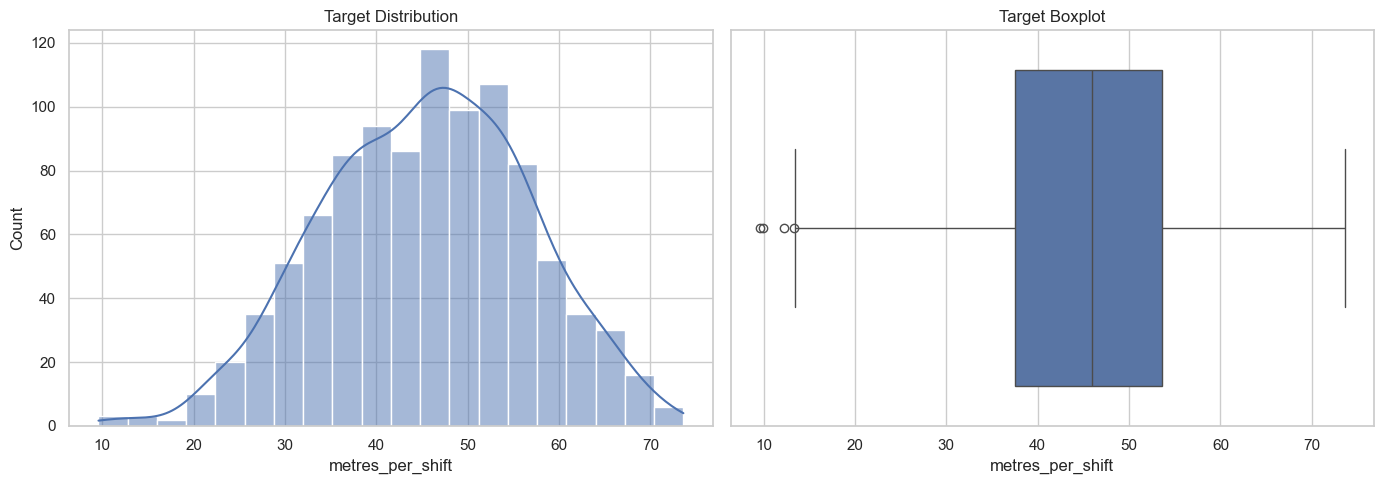

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    train["metres_per_shift"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Target Distribution")

sns.boxplot(
    x=train["metres_per_shift"],
    ax=axes[1]
)

axes[1].set_title("Target Boxplot")

plt.tight_layout()
plt.show()

## Correlation analysis

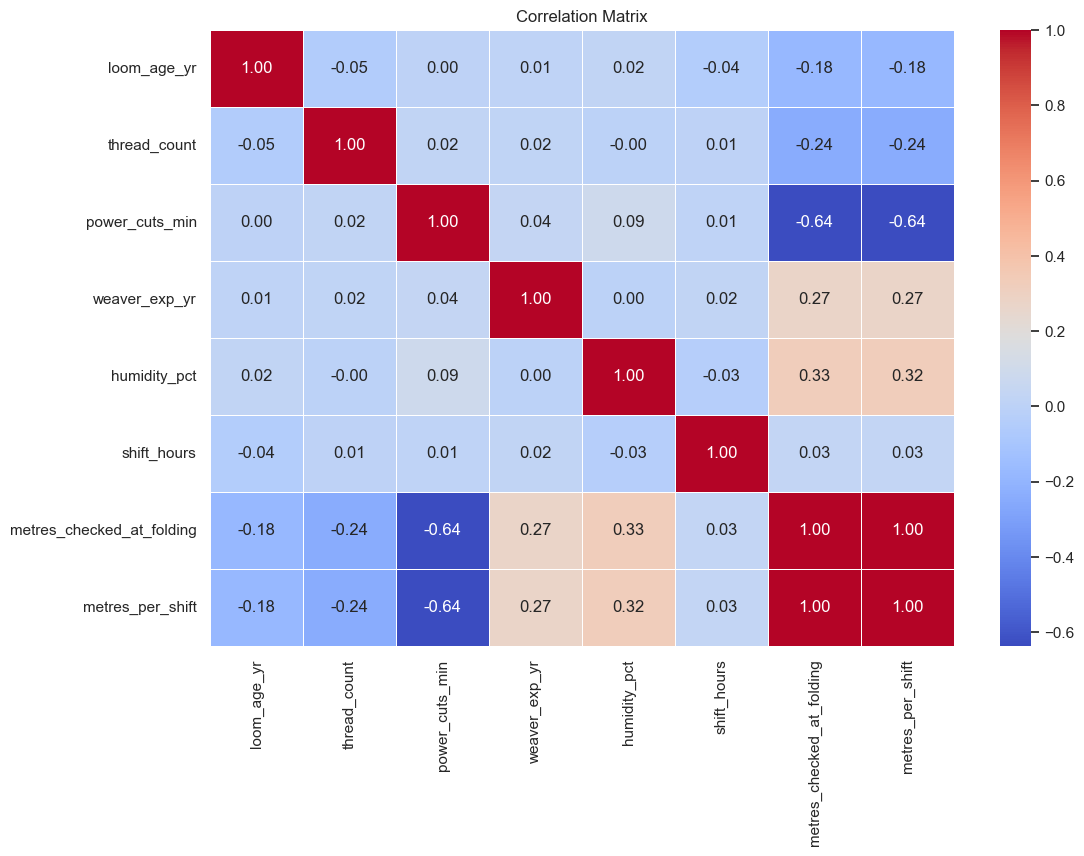

In [20]:
correlation = train[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

In [21]:
target_correlation = correlation["metres_per_shift"].sort_values(
    ascending=False
)

display(target_correlation)

metres_per_shift             1.000000
metres_checked_at_folding    0.998645
humidity_pct                 0.324609
weaver_exp_yr                0.273659
shift_hours                  0.029908
loom_age_yr                 -0.182899
thread_count                -0.243284
power_cuts_min              -0.636893
Name: metres_per_shift, dtype: float64

## Target against individual features

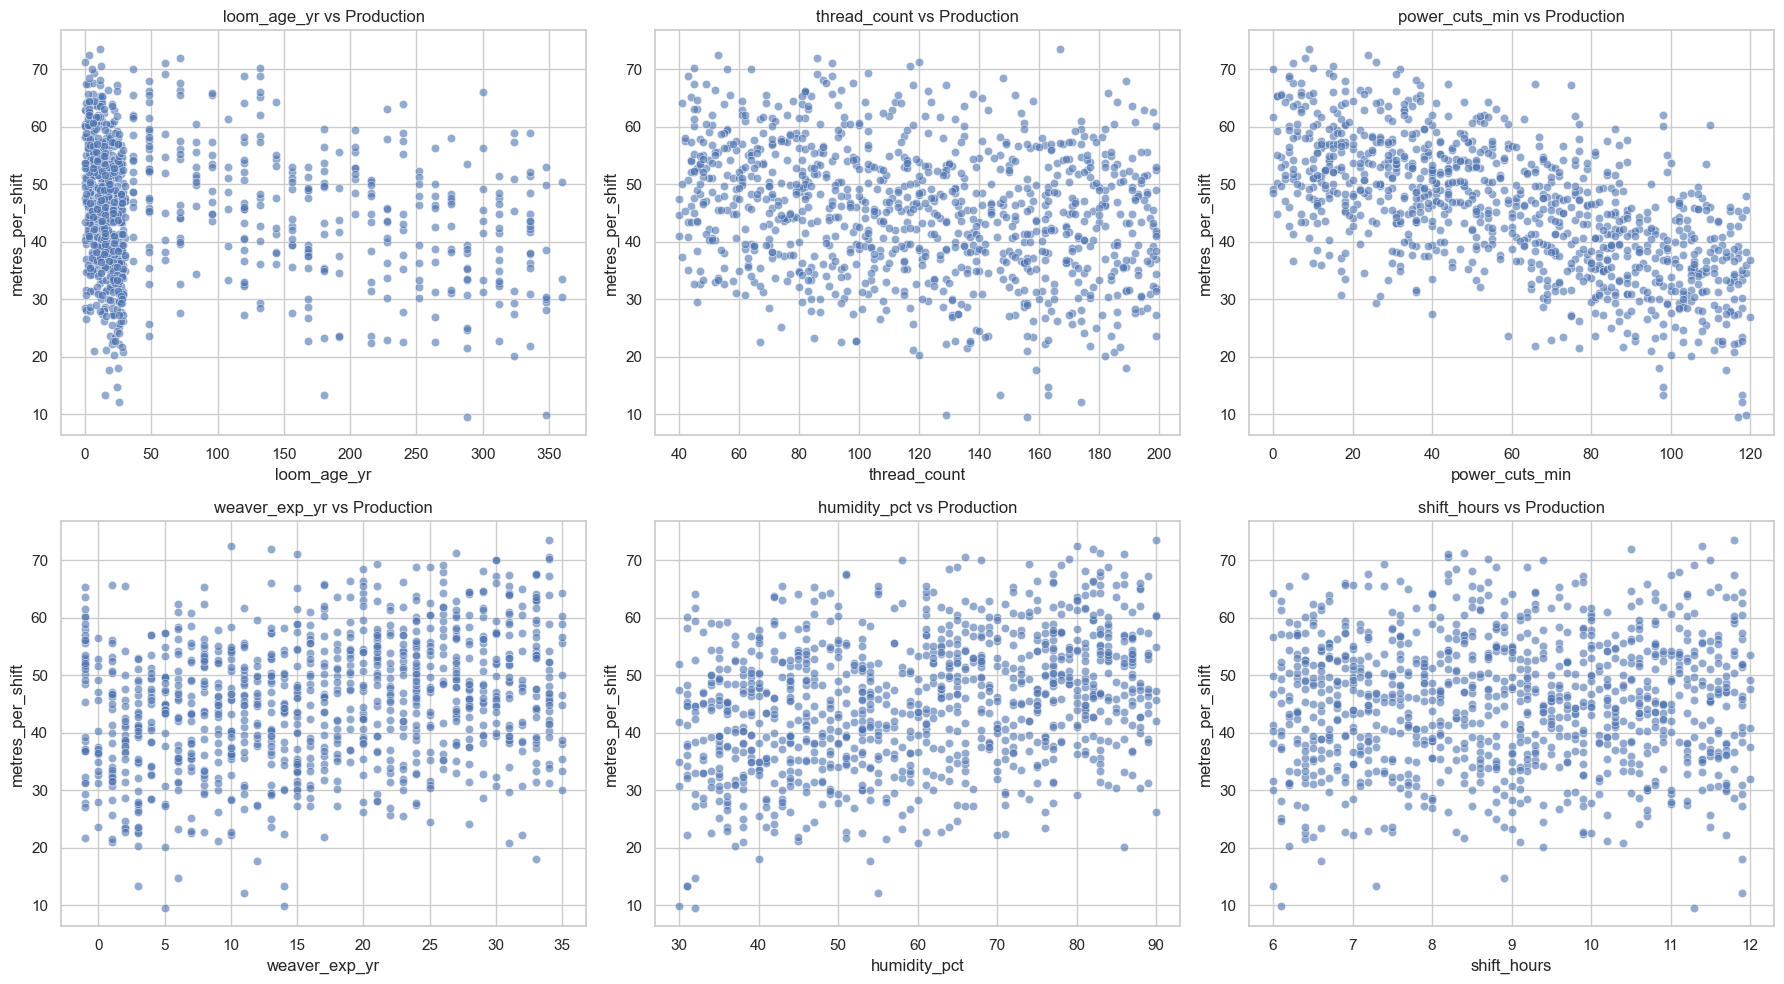

In [22]:
features = [
    "loom_age_yr",
    "thread_count",
    "power_cuts_min",
    "weaver_exp_yr",
    "humidity_pct",
    "shift_hours"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for ax, col in zip(axes, features):

    sns.scatterplot(
        data=train,
        x=col,
        y="metres_per_shift",
        ax=ax,
        alpha=0.6
    )

    ax.set_title(f"{col} vs Production")

plt.tight_layout()
plt.show()

## Analyze data over time

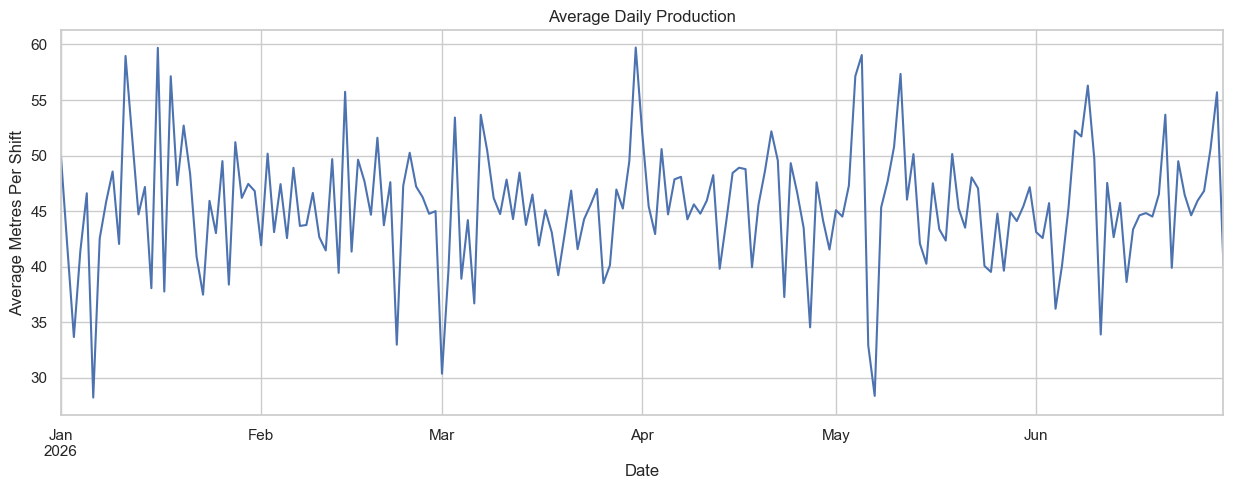

In [23]:
train["date"] = pd.to_datetime(train["date"])

daily_production = train.groupby("date")[
    "metres_per_shift"
].mean()

plt.figure(figsize=(15, 5))

daily_production.plot()

plt.title("Average Daily Production")
plt.xlabel("Date")
plt.ylabel("Average Metres Per Shift")

plt.show()

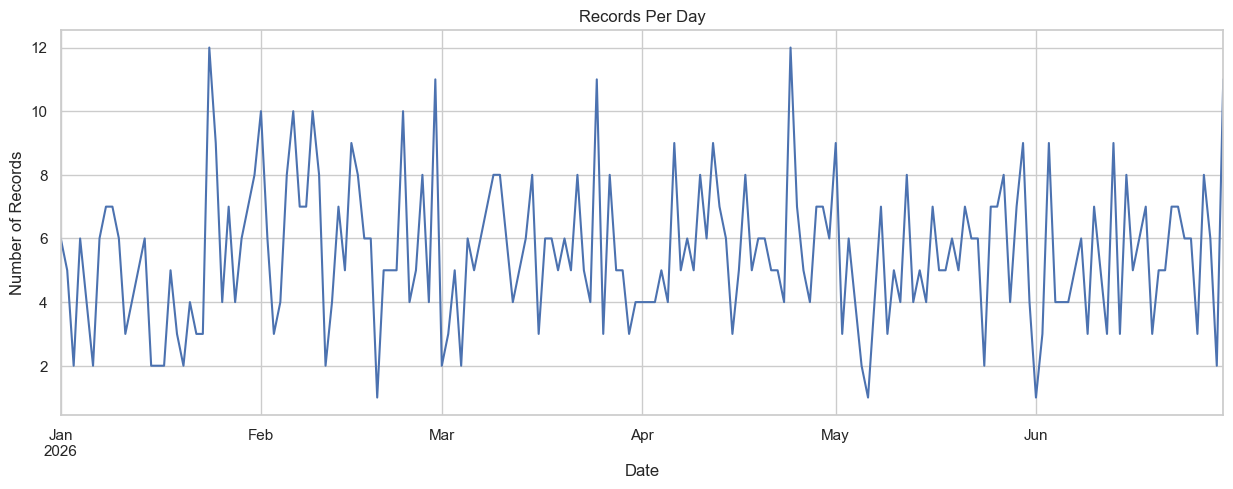

In [24]:
daily_records = train.groupby("date").size()

plt.figure(figsize=(15, 5))

daily_records.plot()

plt.title("Records Per Day")
plt.xlabel("Date")
plt.ylabel("Number of Records")

plt.show()

## Compare training and later datasets

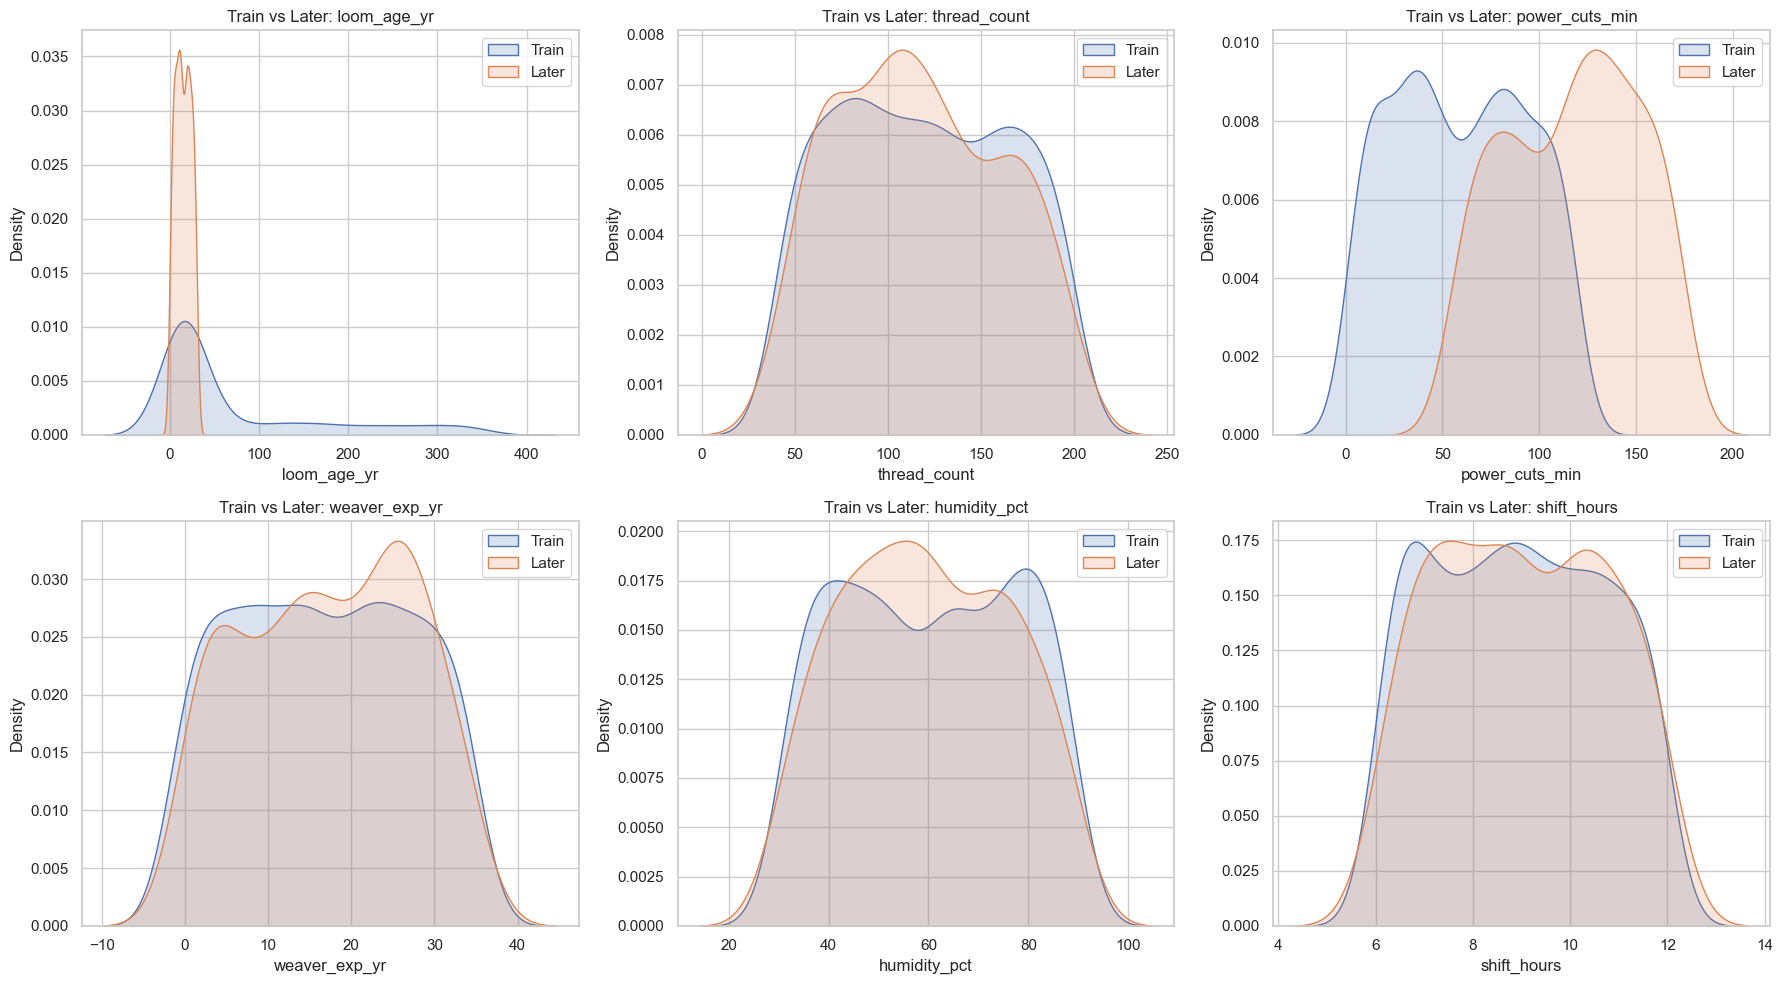

In [25]:
comparison_features = [
    "loom_age_yr",
    "thread_count",
    "power_cuts_min",
    "weaver_exp_yr",
    "humidity_pct",
    "shift_hours"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for ax, col in zip(axes, comparison_features):

    sns.kdeplot(
        data=train,
        x=col,
        ax=ax,
        label="Train",
        fill=True,
        alpha=0.2
    )

    sns.kdeplot(
        data=later,
        x=col,
        ax=ax,
        label="Later",
        fill=True,
        alpha=0.2
    )

    ax.set_title(f"Train vs Later: {col}")
    ax.legend()

plt.tight_layout()
plt.show()

## Check categorical consistency across datasets

In [26]:
for col in categorical_columns:

    print(f"\n{'=' * 40}")
    print(f"TRAIN - {col}")
    print(train[col].value_counts(dropna=False))

    print(f"\nLATER - {col}")
    print(later[col].value_counts(dropna=False))

    print(f"\nHOLDOUT - {col}")
    print(holdout[col].value_counts(dropna=False))


TRAIN - fabric
fabric
cotton        446
polyester     250
silk          154
cotton         21
COTTON         19
 cotton        19
cot.           16
Cotton         13
silk           12
 silk           9
polyester       7
Polyester       7
pol.            6
POLYESTER       6
SILK            5
 polyester      4
Silk            4
sil.            2
Name: count, dtype: int64

LATER - fabric
fabric
cotton       165
polyester     87
silk          48
Name: count, dtype: int64

HOLDOUT - fabric
fabric
cotton       135
polyester     72
silk          43
Name: count, dtype: int64

TRAIN - shed
shed
Shed 3    385
Shed 2    370
Shed 1    245
Name: count, dtype: int64

LATER - shed
shed
Shed 3    110
Shed 2    109
Shed 1     81
Name: count, dtype: int64

HOLDOUT - shed
shed
Shed 2    97
Shed 3    89
Shed 1    64
Name: count, dtype: int64


## Investigate possible data leakage

In [27]:
print("Columns available in TRAIN:")
print(train.columns.tolist())

print("\nColumns available in HOLDOUT:")
print(holdout.columns.tolist())

print("\nColumns missing from HOLDOUT:")

missing_from_holdout = set(train.columns) - set(holdout.columns)

print(missing_from_holdout)

Columns available in TRAIN:
['record_id', 'date', 'loom_age_yr', 'thread_count', 'power_cuts_min', 'weaver_exp_yr', 'humidity_pct', 'shift_hours', 'fabric', 'shed', 'metres_checked_at_folding', 'metres_per_shift']

Columns available in HOLDOUT:
['record_id', 'date', 'loom_age_yr', 'thread_count', 'power_cuts_min', 'weaver_exp_yr', 'humidity_pct', 'shift_hours', 'fabric', 'shed']

Columns missing from HOLDOUT:
{'metres_per_shift', 'metres_checked_at_folding'}


                           metres_checked_at_folding  metres_per_shift
metres_checked_at_folding                   1.000000          0.998645
metres_per_shift                            0.998645          1.000000


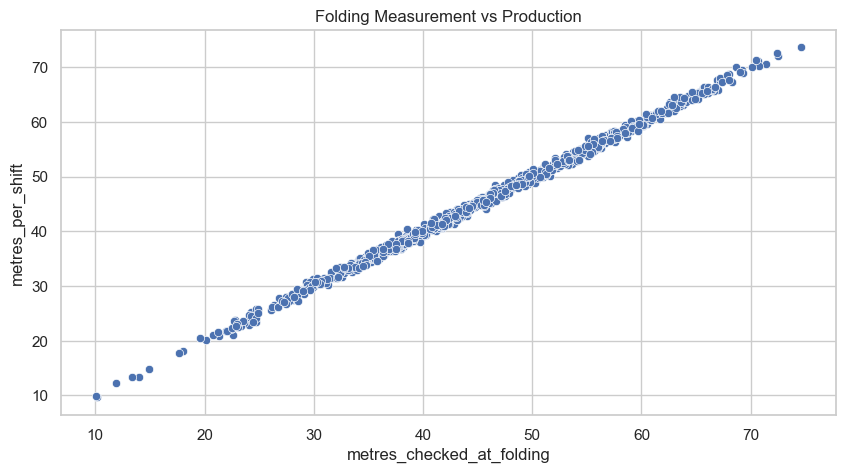

In [28]:
if "metres_checked_at_folding" in train.columns:

    print(
        train[
            ["metres_checked_at_folding", "metres_per_shift"]
        ].corr()
    )

    sns.scatterplot(
        data=train,
        x="metres_checked_at_folding",
        y="metres_per_shift"
    )

    plt.title("Folding Measurement vs Production")
    plt.show()

## Final EDA summary

In [29]:
print("=" * 60)
print("MP212 - EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 60)

print("\nDataset Shapes:")
print("Train:", train.shape)
print("Later:", later.shape)
print("Holdout:", holdout.shape)

print("\nMissing Values in Train:")
print(train.isnull().sum())

print("\nDuplicate Rows:", train.duplicated().sum())

print("\nCategorical Features:")
print(categorical_columns)

print("\nNumerical Features:")
print(numeric_columns)

print("\nTarget Statistics:")
print(train["metres_per_shift"].describe())

print("\nDate Range:")
print(train["date"].min(), "to", train["date"].max())

print("\nEDA COMPLETED!")

MP212 - EXPLORATORY DATA ANALYSIS SUMMARY

Dataset Shapes:
Train: (1000, 12)
Later: (300, 12)
Holdout: (250, 10)

Missing Values in Train:
record_id                    0
date                         0
loom_age_yr                  0
thread_count                 0
power_cuts_min               0
weaver_exp_yr                0
humidity_pct                 0
shift_hours                  0
fabric                       0
shed                         0
metres_checked_at_folding    0
metres_per_shift             0
dtype: int64

Duplicate Rows: 0

Categorical Features:
['fabric', 'shed']

Numerical Features:
['loom_age_yr', 'thread_count', 'power_cuts_min', 'weaver_exp_yr', 'humidity_pct', 'shift_hours', 'metres_checked_at_folding', 'metres_per_shift']

Target Statistics:
count    1000.000000
mean       45.463500
std        11.249733
min         9.600000
25%        37.500000
50%        45.900000
75%        53.600000
max        73.600000
Name: metres_per_shift, dtype: float64

Date Range:
2026-01

## EDA Summary – MP212

1. **Dataset Overview:** Analyzed train, later, and holdout datasets to understand their structure, features, and distributions.

2. **Missing Values:** No null values were detected in any dataset.

3. **Duplicate Records:** No duplicate rows were identified during initial exploration.

4. **Categorical Features:** Analyzed `fabric` and `shed` distributions.

5. **Numerical Analysis:** Used descriptive statistics, histograms, and boxplots to understand feature distributions and potential outliers.

6. **Target Analysis:** Examined `metres_per_shift` as the regression target.

7. **Correlation Analysis:** Identified a correlation of **0.998645** between `metres_checked_at_folding` and `metres_per_shift`.

8. **Data Leakage:** Identified `metres_checked_at_folding` as a leakage column because it is measured after production and is unavailable in the holdout dataset. It will be excluded from model training.

9. **Temporal Analysis:** Examined daily production trends and compared training and later feature distributions.

### Conclusion

EDA provided an understanding of the dataset and revealed a significant data leakage issue. Further investigation of hidden data quality problems, followed by data cleaning and preprocessing, will be performed before model training.